# Comparación de modelos

En este notebook mostramos qué modelo predice mejor si una persona con inversiones vende en una caída, usando la encuesta japonesa. Primero comparamos 7 modelos y después probamos 24 variantes de los mejores para ver si alguno mejoraba.

El entrenamiento no se hace aquí: lo hacen `bolsalab/modeling/train.py` y `bolsalab/modeling/experiments.py`, que guardan sus resultados en `reports/`. Este notebook solo los lee y los muestra. Las reglas (cómo partimos los datos, qué medimos y cómo elegimos al ganador) están en `docs/protocolo-evaluacion.md`, y el resumen de hallazgos en `docs/experimentos.md`.

Todo se midió con el 80 % de entrenamiento (43.763 japoneses), repitiendo 5 veces con grupos distintos. El 20 % de prueba no se ha tocado.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from bolsalab.config import REPORTS_DIR

benchmark = pd.read_csv(REPORTS_DIR / "benchmark.csv")
experiments = pd.read_csv(REPORTS_DIR / "experiments.csv")

MODEL_NAMES = {
    "trivial": "Trivial",
    "logistic": "Regresión logística",
    "random_forest": "Random Forest",
    "xgboost": "XGBoost",
    "lightgbm": "LightGBM",
    "catboost": "CatBoost",
    "neural_net": "Red neuronal",
}

## 1. Los 7 modelos

Cómo leer la tabla:

- **AUROC:** si tomamos al azar una persona que vendió y una que no, qué tan seguido el modelo le da más riesgo a la que vendió. 0,5 es lanzar una moneda y 1 es perfecto.
- **±:** cuánto varió el AUROC entre las 5 repeticiones.
- **AUPRC:** de las personas que el modelo marca como riesgosas, cuántas vendieron. Al azar daría 0,199.
- **Pendiente de calibración:** si el modelo dice 30 %, ¿vende cerca del 30 %? Lo ideal es 1.

In [2]:
table = benchmark.assign(Modelo=benchmark["model"].map(MODEL_NAMES)).set_index("Modelo")
table = table[["auroc", "auroc_sd", "auprc", "brier", "calibration_slope"]].round(3)
table.columns = ["AUROC", "±", "AUPRC", "Brier", "Pendiente de calibración"]
table

,AUROC,±,AUPRC,Brier,Pendiente de calibración
Modelo,,,,,
Trivial,0.500,0.000,0.199,0.159,0.661
Regresión logística,0.646,0.002,0.305,0.152,0.999
Random Forest,0.657,0.004,0.330,0.151,1.228
XGBoost,0.660,0.004,0.331,0.150,1.056
LightGBM,0.660,0.004,0.331,0.150,1.055
CatBoost,0.661,0.004,0.332,0.150,1.096
Red neuronal,0.635,0.018,0.303,0.153,0.823


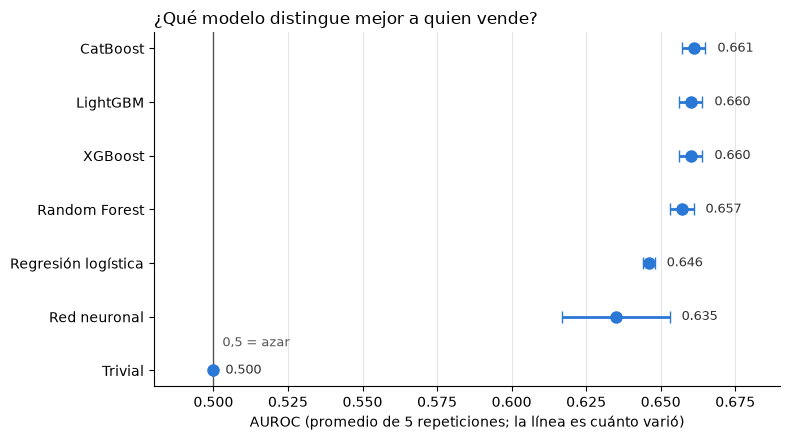

In [3]:
BLUE = "#2a78d6"
order = table.sort_values("AUROC").index

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(table.loc[order, "AUROC"], range(len(order)), xerr=table.loc[order, "±"],
            fmt="o", color=BLUE, markersize=8, capsize=4, linewidth=2)
for y, model in enumerate(order):
    ax.text(table.loc[model, "AUROC"] + table.loc[model, "±"] + 0.004, y, f"{table.loc[model, 'AUROC']:.3f}",
            va="center", fontsize=9, color="#333333")
ax.axvline(0.5, color="#555555", linewidth=1)
ax.text(0.503, 0.45, "0,5 = azar", color="#555555", fontsize=9)
ax.set_yticks(range(len(order)), order)
ax.set_xlim(0.48, 0.69)
ax.set_xlabel("AUROC (promedio de 5 repeticiones; la línea es cuánto varió)")
ax.set_title("¿Qué modelo distingue mejor a quien vende?", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e5e5e5")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### Cómo se elige al ganador

La regla del protocolo: gana el de mayor AUROC, salvo que un modelo más simple quede a menos de una desviación del mejor; entonces gana el más simple. El orden de "más simple a más complejo" es el de la tabla.

In [4]:
best = benchmark.loc[benchmark["auroc"].idxmax()]
cutoff = best["auroc"] - best["auroc_sd"]
winner = benchmark[benchmark["auroc"] >= cutoff].iloc[0]["model"]
print(f"Mejor AUROC: {MODEL_NAMES[best['model']]} ({best['auroc']:.4f} ± {best['auroc_sd']:.4f})")
print(f"Entran los modelos con AUROC de al menos {cutoff:.4f}")
print(f"Ganador por la regla: {MODEL_NAMES[winner]}")

Mejor AUROC: CatBoost (0.6613 ± 0.0039)
Entran los modelos con AUROC de al menos 0.6573
Ganador por la regla: XGBoost


**Qué significa.** Todos los modelos aprendieron algo, porque superan al trivial. Los cuatro de árboles quedaron casi empatados (0,657 a 0,661), apenas por encima de la regresión logística (0,646): la señal del cuestionario es real pero sencilla. La red neuronal quedó de última y fue la más inestable. Gana XGBoost porque CatBoost lo supera por 0,001, menos que la variación normal entre repeticiones.

## 2. Los 24 experimentos

Tomamos los tres mejores modelos (XGBoost, LightGBM y CatBoost) y probamos:

- **Dos rejillas de ajustes:** la del protocolo y una más amplia. Una rejilla es la lista de combinaciones de ajustes que se prueban, como la profundidad de los árboles o qué tan rápido aprende el modelo.
- **Cuatro versiones de las variables:** sin cambios, sin la edad al cuadrado, con el logaritmo del ingreso y multiplicando edad por ingreso.

Para reemplazar a XGBoost, un experimento tenía que superar su AUROC por más de una desviación. Esa regla quedó en el protocolo antes de correrlos.

In [5]:
FEATURE_NAMES = {
    "base": "Sin cambios",
    "sin_edad_cuadrado": "Sin edad al cuadrado",
    "log_ingreso": "Logaritmo del ingreso",
    "edad_x_ingreso": "Edad por ingreso",
}
grid = experiments.pivot_table(index=["model", "features"], columns=experiments["experiment"].str.split("|").str[2],
                               values="auroc").round(4)
grid.index = [f"{MODEL_NAMES[m]} · {FEATURE_NAMES[f]}" for m, f in grid.index]
grid.columns = [f"Rejilla {c}" for c in grid.columns]
grid

,Rejilla ampliada,Rejilla protocolo
CatBoost · Sin cambios,0.6610,0.6613
CatBoost · Edad por ingreso,0.6605,0.6605
CatBoost · Logaritmo del ingreso,0.6610,0.6613
CatBoost · Sin edad al cuadrado,0.6609,0.6609
LightGBM · Sin cambios,0.6601,0.6600
LightGBM · Edad por ingreso,0.6594,0.6596
LightGBM · Logaritmo del ingreso,0.6601,0.6600
LightGBM · Sin edad al cuadrado,0.6601,0.6600
XGBoost · Sin cambios,0.6607,0.6601
XGBoost · Edad por ingreso,0.6603,0.6598


In [6]:
xgb = benchmark.set_index("model").loc["xgboost"]
threshold = xgb["auroc"] + xgb["auroc_sd"]
top = experiments.loc[experiments["auroc"].idxmax()]
print(f"Para reemplazar a XGBoost había que pasar de {threshold:.4f}")
print(f"El mejor experimento fue {top['experiment']} con {top['auroc']:.4f}")
print("¿Alguno reemplaza a XGBoost?", "Sí" if (experiments["auroc"] > threshold).any() else "No")

Para reemplazar a XGBoost había que pasar de 0.6636
El mejor experimento fue catboost|base|protocolo con 0.6613
¿Alguno reemplaza a XGBoost? No


**Qué significa.**

- **Ajustar más no mejora.** Los 24 quedaron entre 0,659 y 0,661. El modelo ya sacó lo que el cuestionario permite.
- **Las transformaciones no cambian nada en los árboles.** Quitar la edad al cuadrado o sacar el logaritmo del ingreso da exactamente el mismo resultado: los árboles cortan por "mayor o menor que", y esas transformaciones no cambian el orden de las personas. Multiplicar edad por ingreso empeora un poco.

## 3. Qué ajustes eligieron

En cada una de las 5 repeticiones, el modelo eligió su mejor combinación de ajustes. Si siempre elige la misma, el resultado es estable.

In [7]:
def chosen(params_json):
    folds = json.loads(params_json)
    distinct = {json.dumps(f, sort_keys=True) for f in folds}
    return len(distinct), "; ".join(
        ", ".join(f"{k.replace('model__', '')}={v}" for k, v in json.loads(d).items()) for d in sorted(distinct))


rows = experiments[experiments["features"] == "base"]
choices = pd.DataFrame(
    [(MODEL_NAMES[r.model], r.experiment.split("|")[2], *chosen(r.best_params)) for r in rows.itertuples()],
    columns=["Modelo", "Rejilla", "Combinaciones distintas en 5 repeticiones", "Ajustes elegidos"],
).set_index(["Modelo", "Rejilla"])
choices

Combinaciones distintas en 5 repeticiones  \
Modelo   Rejilla                                                
XGBoost  protocolo                                          1   
         ampliada                                           1   
LightGBM protocolo                                          1   
         ampliada                                           1   
CatBoost protocolo                                          2   
         ampliada                                           3   

                                                     Ajustes elegidos  
Modelo   Rejilla                                                       
XGBoost  protocolo                    learning_rate=0.03, max_depth=3  
         ampliada   learning_rate=0.03, max_depth=3, min_child_wei...  
LightGBM protocolo                    learning_rate=0.03, max_depth=3  
         ampliada   learning_rate=0.03, max_depth=3, min_child_sam...  
CatBoost protocolo  depth=4, learning_rate=0.03; depth=6, learning...  
         ampliada   depth=4, l2_leaf_reg=10, learning_rate=0.03; d...

**Qué significa.** XGBoost y LightGBM eligieron los mismos ajustes en las 5 repeticiones, así que el resultado no depende del reparto de personas. CatBoost dudó entre profundidad 4 y 6.

Todos eligieron la profundidad más baja disponible (3) y, en la rejilla ampliada, las opciones más conservadoras: hojas con más personas y menos hojas. Los modelos piden ser simples, así que no vale la pena buscar configuraciones más complejas.

## 4. Calibración

La pendiente de calibración dice si las probabilidades del modelo tienen el tamaño correcto. Con 1 están bien; por encima de 1, salen apretadas hacia el promedio.

In [8]:
calibration = experiments[experiments["features"] == "base"].assign(
    Modelo=lambda d: d["model"].map(MODEL_NAMES),
    Rejilla=lambda d: d["experiment"].str.split("|").str[2],
).set_index(["Modelo", "Rejilla"])[["auroc", "calibration_slope"]].round(3)
calibration.columns = ["AUROC", "Pendiente de calibración"]
calibration

AUROC  Pendiente de calibración
Modelo   Rejilla                                   
XGBoost  protocolo  0.660                     1.056
         ampliada   0.661                     1.037
LightGBM protocolo  0.660                     1.055
         ampliada   0.660                     1.056
CatBoost protocolo  0.661                     1.096
         ampliada   0.661                     1.093

**Qué significa.** XGBoost es el mejor calibrado de los tres (1,04 a 1,06) y CatBoost el peor (1,08 a 1,11). Ninguno llega a 1, así que más adelante puede valer la pena recalibrar. La regla para elegir al ganador solo mira el AUROC, pero esto es otro punto a favor de XGBoost.

## Conclusión

- **XGBoost es el ganador,** con velocidad de aprendizaje 0,03 y profundidad 3.
- **El techo es el cuestionario, no el modelo:** 7 modelos y 24 variantes quedaron alrededor de 0,66. Concuerda con el estudio original, que reporta un pseudo R² menor de 0,04 con estas variables.
- **Los modelos simples bastan:** la regresión logística queda a 0,014 del mejor y los árboles prefieren poca profundidad.

## Lo que falta

- Medir a XGBoost una sola vez en el 20 % de prueba. Ese será su resultado oficial.
- Explicar sus predicciones con SHAP.
- Probarlo en EE. UU. con la NFCS.